# Using Machine Learning to Solve for State of trend
Change approach of problem. Don't treat it as a time problem. Treat it as a state problem.
- Instead oftrying to predict it at n=0, try to predict if its a strong trend before it hits n.
- Example: at n=3, algorithm can figure out trend is n=10.

In [1]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
from utils.indicators import *
from utils.engine import *

df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")
# Convert unix timestamp to datetime
df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')  # change unit to 's' if in seconds
df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

# Set datetime as index
df_orderbook = df_orderbook.set_index('datetime')
df_trades = df_trades.set_index('datetime')

# Aggregate orderbook to 1m (mid-price OHLCV style)
df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2
df_ob_1m = df_orderbook.resample('1min').agg({
    'mid_price': ['first', 'max', 'min', 'last'],
    'bid_price': 'last',
    'ask_price': 'last',
    'bid_amount': 'sum',
    'ask_amount': 'sum',
})
df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']

df_ob_1m['mid_price'] = (df_ob_1m['bid_price'] + df_ob_1m['ask_price']) / 2
df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

df_trades['buy_vol']  = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

# Aggregate trades to 1m
df_trades_1m = df_trades.resample('1min').agg({
    'price': ['first', 'max', 'min', 'last', 'count'],
    'amount': 'sum',
    'buy_vol': ['sum', 'max'],
    'sell_vol': ['sum', 'max']
})

# Flatten multi-level columns
df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume', 'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']

df_trades_1m = df_trades_1m.dropna(subset=['close'])

df_price_1m = pd.DataFrame({
    'open': df_ob_1m['open'],
    'high': df_ob_1m['high'],
    'low': df_ob_1m['low'],
    'close': df_ob_1m['close'],
    'largest_buyer': df_trades_1m['largest_buyer'] * 100 / df_trades_1m['volume'],
    'largest_seller': df_trades_1m['largest_seller'] * 100 / df_trades_1m['volume'],
    'OFI_LOB': 100*(df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount']),
    'OFI_AGG': 100*(df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller']),
    'vol_ratio': np.random.rand(len(df_ob_1m)),
    'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / abs(df_ob_1m['high'] - df_ob_1m['low']),
    'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / (df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean(),
})
df_price_1m

,open,high,low,close,largest_buyer,largest_seller,OFI_LOB,OFI_AGG,vol_ratio,candle_type,candle_size
datetime,,,,,,,,,,,
2026-06-28 08:59:00,60343.75,60343.75,60337.35,60337.35,14.248252,23.688811,-74.522379,-39.219114,0.327488,1.000000,NaN
2026-06-28 09:00:00,60337.35,60353.45,60334.95,60344.15,7.280285,7.939430,-26.065918,-0.142518,0.383793,0.367568,NaN
2026-06-28 09:01:00,60344.15,60348.75,60311.65,60318.35,4.612850,5.826469,-18.319465,-59.648545,0.745916,0.695418,NaN
2026-06-28 09:02:00,60318.35,60338.15,60318.35,60338.15,7.604817,5.352364,43.894900,8.206958,0.964484,1.000000,NaN
2026-06-28 09:03:00,60338.15,60338.15,60276.75,60286.25,3.312667,3.344345,-19.263835,-13.743947,0.081076,0.845277,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2026-06-29 19:53:00,60508.15,60533.15,60468.75,60468.75,3.119896,1.976632,40.092069,3.145023,0.457226,0.611801,1.267984
2026-06-29 19:54:00,60468.75,60468.75,60382.95,60449.05,3.648344,1.622929,43.872191,19.243066,0.817247,0.229604,1.560912
2026-06-29 19:55:00,60449.05,60512.75,60449.05,60469.95,2.990614,0.540423,35.079997,78.911297,0.895956,0.328100,1.116774


# Extracting Target Variable and Advanced Data Manipulation

Usable samples: 537  across 97 streaks

Class distribution:
target
Short (<=3)       59
Medium (4-10)    226
Long (>10)       252
Name: count, dtype: int64

-- Overall classification report --------------------------------
               precision    recall  f1-score   support

  Short (<=3)       0.35      0.46      0.40        13
Medium (4-10)       0.31      0.55      0.40        40
   Long (>10)       0.33      0.10      0.15        50

     accuracy                           0.32       103
    macro avg       0.33      0.37      0.32       103
 weighted avg       0.33      0.32      0.28       103


-- Accuracy / Long-recall by bars into the streak ----------------
  duration_so_far= 1:  n=   20  acc=0.350  long_recall=0.000
  duration_so_far= 2:  n=   14  acc=0.214  long_recall=0.000
  duration_so_far= 3:  n=   12  acc=0.333  long_recall=0.000
  duration_so_far= 4:  n=   11  acc=0.364  long_recall=0.000
  duration_so_far= 5:  n=   10  acc=0.400  long_recall=0.000
  duration_so_fa

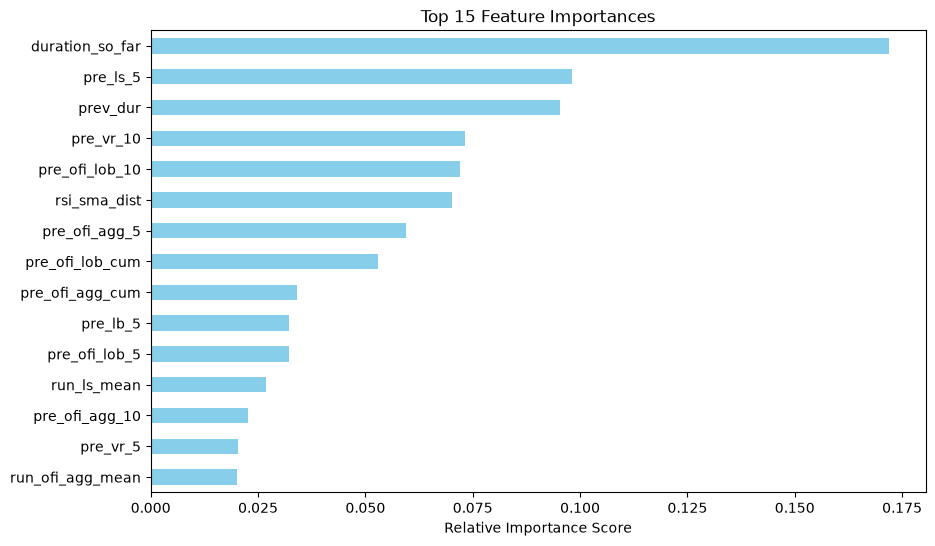

In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, f1_score
import warnings
warnings.filterwarnings('ignore')

df = df_price_1m.reset_index(drop=True).copy()

# ─────────────────────────────────────────────────────────────────────────────
# 0 · Streak / block setup (unchanged from before)
# ─────────────────────────────────────────────────────────────────────────────
df['rsi_above_sma'] = df['rsi_14'] > df['sma_14']
df['block'] = (df['rsi_above_sma'] != df['rsi_above_sma'].shift()).cumsum()
df['streak_dur'] = df.groupby('block')['block'].transform('count')

is_start        = df['block'] != df['block'].shift()
start_positions = df.index[is_start].tolist()

CLASS_NAMES = ['Short (<=3)', 'Medium (4-10)', 'Long (>10)']

def label(d):
    return 0 if d <= 3 else (1 if d <= 10 else 2)
    # If you only care about Long vs Not-Long, swap this for:
    # return int(d > 10)   and set CLASS_NAMES = ['Not Long', 'Long']

# ─────────────────────────────────────────────────────────────────────────────
# 1 · Feature extraction — ONE ROW PER (streak, elapsed bar), not per streak
#
#     elapsed = 0 is the crossover bar itself, elapsed = 1 is one bar later,
#     etc. We stop sampling once duration_so_far hits MAX_ELAPSED, because
#     past that point "Long" is no longer a prediction, it's already true.
#
#     Two kinds of features:
#       - pre_*  : fixed at streak start, describing the run-up BEFORE the
#                  crossover. Same for every elapsed step in a given streak.
#       - run_*  : recomputed at every elapsed step using ONLY bars from
#                  start..current bar (inclusive). This is what lets the
#                  model update its read as the streak develops, without
#                  ever seeing bars that haven't happened yet.
# ─────────────────────────────────────────────────────────────────────────────

LOOKBACK    = 10   # bars of pre-streak history for the run-up features
MAX_ELAPSED = 10   # only sample while the streak is still <=10 bars old

records = []

for i, start in enumerate(start_positions):
    if start < LOOKBACK:
        continue

    final_dur  = df.at[start, 'streak_dur']
    prev_start = start_positions[i - 1] if i > 0 else None
    prev_dur   = df.at[prev_start, 'streak_dur'] if prev_start is not None else np.nan

    # ── Pre-streak run-up window: fixed once per streak, no leakage ─────────
    pre = df.iloc[start - LOOKBACK: start]
    pre_ofi_lob_5   = pre.tail(5)['OFI_LOB'].mean()
    pre_ofi_agg_5   = pre.tail(5)['OFI_AGG'].mean()
    pre_ofi_lob_10  = pre['OFI_LOB'].mean()
    pre_ofi_agg_10  = pre['OFI_AGG'].mean()
    pre_ofi_lob_cum = pre['OFI_LOB'].sum()
    pre_ofi_agg_cum = pre['OFI_AGG'].sum()
    pre_vr_5        = pre.tail(5)['vol_ratio'].mean()
    pre_vr_10       = pre['vol_ratio'].mean()
    pre_lb_5        = pre.tail(5)['largest_buyer'].mean()
    pre_ls_5        = pre.tail(5)['largest_seller'].mean()

    start_dist = df.at[start, 'rsi_14'] - df.at[start, 'sma_14']

    n_samples = min(final_dur, MAX_ELAPSED)

    for elapsed in range(n_samples):
        pos = start + elapsed
        if pos >= len(df):
            break

        row = df.loc[pos]
        duration_so_far = elapsed + 1   # what you'd actually know live

        # ── Causal in-streak accumulation: start..pos only ──────────────────
        in_streak = df.iloc[start: pos + 1]
        run_ofi_lob_mean = in_streak['OFI_LOB'].mean()
        run_ofi_agg_mean = in_streak['OFI_AGG'].mean()
        run_ofi_lob_sum  = in_streak['OFI_LOB'].sum()
        run_ofi_agg_sum  = in_streak['OFI_AGG'].sum()
        run_vr_mean      = in_streak['vol_ratio'].mean()
        run_candle_size  = in_streak['candle_size'].mean()
        run_candle_type  = in_streak['candle_type'].mean()
        run_lb_mean      = in_streak['largest_buyer'].mean()
        run_ls_mean      = in_streak['largest_seller'].mean()

        rsi          = row['rsi_14']
        sma_val      = row['sma_14']
        rsi_sma_dist = rsi - sma_val
        dist_change_since_start = rsi_sma_dist - start_dist

        rsi_d3 = rsi - df.at[max(pos - 3, 0), 'rsi_14']
        rsi_d5 = rsi - df.at[max(pos - 5, 0), 'rsi_14']

        lb, ls   = row['largest_buyer'], row['largest_seller']
        bs_ratio = lb / (ls + 1e-9)

        rec = {
            # ── The key new feature: how far into the streak are we ────────
            'duration_so_far':  duration_so_far,

            # RSI state right now
            'rsi':              rsi,
            'rsi_sma_dist':     rsi_sma_dist,
            'rsi_vs_50':        rsi - 50,
            'rsi_d3':           rsi_d3,
            'rsi_d5':           rsi_d5,
            'dist_change':      dist_change_since_start,
            'direction':        int(row['rsi_above_sma']),

            # Order flow — current bar
            'ofi_lob':          row['OFI_LOB'],
            'ofi_agg':          row['OFI_AGG'],
            'ofi_alignment':    int(np.sign(row['OFI_LOB']) == np.sign(row['OFI_AGG'])),

            # Order flow — pre-streak run-up (fixed per streak)
            'pre_ofi_lob_5':    pre_ofi_lob_5,
            'pre_ofi_agg_5':    pre_ofi_agg_5,
            'pre_ofi_lob_10':   pre_ofi_lob_10,
            'pre_ofi_agg_10':   pre_ofi_agg_10,
            'pre_ofi_lob_cum':  pre_ofi_lob_cum,
            'pre_ofi_agg_cum':  pre_ofi_agg_cum,

            # Order flow — accumulated WITHIN the streak so far (grows with elapsed)
            'run_ofi_lob_mean': run_ofi_lob_mean,
            'run_ofi_agg_mean': run_ofi_agg_mean,
            'run_ofi_lob_sum':  run_ofi_lob_sum,
            'run_ofi_agg_sum':  run_ofi_agg_sum,

            # Volume
            'vol_ratio':        row['vol_ratio'],
            'pre_vr_5':         pre_vr_5,
            'pre_vr_10':        pre_vr_10,
            'run_vr_mean':      run_vr_mean,

            # Buyer / seller
            'largest_buyer':    lb,
            'largest_seller':   ls,
            'bs_ratio':         bs_ratio,
            'pre_lb_5':         pre_lb_5,
            'pre_ls_5':         pre_ls_5,
            'run_lb_mean':      run_lb_mean,
            'run_ls_mean':      run_ls_mean,

            # Candle
            'candle_type':      row['candle_type'],
            'candle_size':      row['candle_size'],
            'run_candle_size':  run_candle_size,
            'run_candle_type':  run_candle_type,

            # Memory of the previous completed streak
            'prev_dur':         prev_dur,

            # Bookkeeping — not used as model features
            'block':            df.at[start, 'block'],
            'target':           label(final_dur),
            'final_dur':        final_dur,
        }
        records.append(rec)

feat_df = pd.DataFrame(records).dropna()
print(f"Usable samples: {len(feat_df)}  across {feat_df['block'].nunique()} streaks")
print("\nClass distribution:")
print(feat_df['target'].value_counts().sort_index()
      .rename(index=dict(enumerate(CLASS_NAMES))))

# ─────────────────────────────────────────────────────────────────────────────
# 2 · Train / test split — split by STREAK (block), not by row, so a single
#     streak's bars never straddle the train/test boundary
# ─────────────────────────────────────────────────────────────────────────────
META  = ['target', 'final_dur', 'block']
FEATS = [c for c in feat_df.columns if c not in META]

blocks    = feat_df['block'].drop_duplicates().sort_values()
cut_block = blocks.iloc[int(len(blocks) * 0.80)]

train_mask = feat_df['block'] < cut_block
test_mask  = ~train_mask

X_tr, y_tr = feat_df.loc[train_mask, FEATS].values, feat_df.loc[train_mask, 'target'].values
X_te, y_te = feat_df.loc[test_mask,  FEATS].values, feat_df.loc[test_mask,  'target'].values

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

sw_tr = compute_sample_weight('balanced', y_tr)

# ─────────────────────────────────────────────────────────────────────────────
# 3 · Train
# ─────────────────────────────────────────────────────────────────────────────
clf = GradientBoostingClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=5, random_state=42,
)
clf.fit(X_tr_s, y_tr, sample_weight=sw_tr)

# ─────────────────────────────────────────────────────────────────────────────
# 4 · Evaluate — overall, AND broken down by how far into the streak we are.
#     This second part is the part that actually answers "how early can we
#     detect a long streak forming" — accuracy at duration_so_far=1 vs =5 vs =9.
# ─────────────────────────────────────────────────────────────────────────────
present_classes = sorted(np.unique(np.concatenate([y_tr, y_te])))
present_names   = [CLASS_NAMES[c] for c in present_classes]

y_pred = clf.predict(X_te_s)

print("\n-- Overall classification report --------------------------------")
print(classification_report(y_te, y_pred, labels=present_classes, target_names=present_names))

test_df = feat_df.loc[test_mask].copy()
test_df['pred'] = y_pred

print("\n-- Accuracy / Long-recall by bars into the streak ----------------")
for d in sorted(test_df['duration_so_far'].unique()):
    sub = test_df[test_df['duration_so_far'] == d]
    acc = (sub['pred'] == sub['target']).mean()
    long_class = present_classes[-1]
    actual_long = sub[sub['target'] == long_class]
    long_recall = (actual_long['pred'] == long_class).mean() if len(actual_long) else np.nan
    print(f"  duration_so_far={d:>2}:  n={len(sub):>5}  acc={acc:.3f}  "
          f"long_recall={long_recall:.3f}" if not np.isnan(long_recall)
          else f"  duration_so_far={d:>2}:  n={len(sub):>5}  acc={acc:.3f}  long_recall=n/a")

import matplotlib.pyplot as plt

feature_importances = pd.Series(clf.feature_importances_, index=FEATS)
top_15 = feature_importances.nlargest(15)

plt.figure(figsize=(10, 6))
top_15.plot(kind='barh', color='skyblue')
plt.title("Top 15 Feature Importances")
plt.xlabel("Relative Importance Score")
plt.gca().invert_yaxis()
plt.show()